# EquityAgent: An Autonomous Agentic Workflow for Investment Research

**GitHub repository:** https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final (branch `main`)

MS in Applied AI, University of San Diego. AAI-520: NLP and Generative AI,
final project.

**Team:** Data lead, NLP lead, Agent lead (Nicole Rowley), Evaluation lead.

EquityAgent researches a stock ticker end to end: it plans the research,
calls market, macro, news and SEC-filing tools, runs a five-step prompt
chain over the news, routes each task to a specialist, writes a brief,
grades and revises it, reflects on the run, and stores lessons that change
the next run's plan. Demo tickers: NVDA, JPM, XOM.

| Part | Contents | Assignment heading |
|---|---|---|
| A | Data check, Kaggle news EDA, classifier evaluation | Agent Functions and Capabilities |
| B | One agent run with every step printed | Agent Design and Workflows |
| C | Baseline comparison, memory ablation, limitations | Evaluation and Iteration |

**Models.** Planner, router and news chain: `gpt-6-luna`. Writer and
optimizer: `claude-sonnet-5`. Evaluator: `gpt-6-sol` (a different family
from the writer, so the draft is not graded by the model that wrote it).
Embeddings: `all-MiniLM-L6-v2`.


## Setup

In [2]:
# --- Colab setup -----------------------------------------------------
import os
import sys

from google.colab import drive, userdata

os.chdir("/content")
drive.mount("/content/drive")

BRANCH = "nlp-track-ashley"
REPO = "/content/drive/MyDrive/equity-agent-nlp"  # not the team's folder
REPO_URL = "https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final.git"

if os.path.isdir(os.path.join(REPO, ".git")):
    !git -C {REPO} fetch -q origin
    !git -C {REPO} checkout -q {BRANCH}
    !git -C {REPO} pull -q
else:
    !git clone -q --branch {BRANCH} {REPO_URL} {REPO}
%cd {REPO}
sys.path.insert(0, REPO)
!git log -1 --format='%h %an  %s'

SKIP = r"google-adk\|dependency resolver"
!pip install -q -r requirements.txt 2>&1 | grep -v "{SKIP}"

SECRET_KEYS = [
    "OPENAI_API_KEY",
    "ANTHROPIC_API_KEY",
    "FRED_API_KEY",
    "NEWSAPI_KEY",
    "EDGAR_USER_AGENT",
    "KAGGLE_API_TOKEN",
]
loaded = []
for key in SECRET_KEYS:
    try:
        os.environ[key] = userdata.get(key)
        loaded.append(key)
    except Exception:
        print(f"Missing secret: {key}")
print("Loaded:", loaded)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/equity-agent-nlp
100600d Ashley Figueroa  NLP track: classifier diagnostics, few-shot prompts, chain fixes
Loaded: ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'FRED_API_KEY', 'NEWSAPI_KEY', 'EDGAR_USER_AGENT', 'KAGGLE_API_TOKEN']


In [3]:
import logging
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="huggingface_hub")

from src import display as show  # noqa: E402
from src.config import TICKERS  # noqa: E402
from src.evaluation import (  # noqa: E402
    baseline_brief,
    quick_smoke,
    score_against_findings,
    tool_success_rate,
    unsupported_figures,
)
from src.graph import run_agent  # noqa: E402
from src.memory import store  # noqa: E402
from src.tools import safe_call  # noqa: E402
from src.tools.retrieval import index_filings  # noqa: E402

pd.set_option("display.max_colwidth", 120)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

# Part A. Data and NLP

## Agent Functions and Capabilities

The agent's tools and the news prompt chain are built and tested before
the agent uses them. This part checks each data source (yfinance, FRED,
NewsAPI, SEC EDGAR), explores the Kaggle financial-news dataset used to
benchmark the sentiment classifier, and compares the LLM classifier with
a keyword baseline and a supervised TF-IDF baseline, with zero-shot and
few-shot prompts, broken down by annotator agreement. Every tool call
goes through `safe_call`, so a failed API shows as `ok=False` instead of
stopping the notebook.


## A1. Data check: does every tool return data?

Each call goes through `safe_call`, so a failed API shows as `ok=False`
instead of stopping the notebook.

In [4]:
from src.tools.filings import extract_sections, get_latest_10k
from src.tools.macro import get_macro_snapshot
from src.tools.market import compute_technicals, get_price_history
from src.tools.news import get_news


def status(result):
    """Every ToolResult field except the data itself."""
    return {k: v for k, v in vars(result).items() if k != "data"}


checks = []
spy = safe_call("prices", get_price_history, "SPY")
for ticker in TICKERS:
    prices = safe_call("prices", get_price_history, ticker)
    checks.append({"ticker": ticker, **status(prices)})
    if prices.ok and spy.ok:
        print(ticker, compute_technicals(prices.data, spy.data))

macro = safe_call("fred", get_macro_snapshot)
checks.append({"ticker": "-", **status(macro)})
pd.DataFrame(checks)

NVDA {'last_close': 214.13, 'return_1m': -0.0238, 'return_1y': 0.1907, 'vol_annualized': 0.3727, 'sma_50': 223.08, 'sma_200': 202.97, 'beta_vs_spy': 2.128}
JPM {'last_close': 339.72, 'return_1m': -0.0275, 'return_1y': 0.1113, 'vol_annualized': 0.2217, 'sma_50': 348.12, 'sma_200': 322.37, 'beta_vs_spy': 0.871}
XOM {'last_close': 178.98, 'return_1m': 0.0962, 'return_1y': 0.6036, 'vol_annualized': 0.2603, 'sma_50': 163.69, 'sma_200': 151.72, 'beta_vs_spy': 0.383}


,ticker,tool,ok,error,meta
0,NVDA,prices,True,None,{'rows': 1255}
1,JPM,prices,True,None,{'rows': 1255}
2,XOM,prices,True,None,{'rows': 1255}
3,-,fred,True,None,{'rows': 5}


In [5]:
macro.data if macro.ok else macro.error

,series,label,date,latest,one_year_ago
0,CPIAUCSL,"CPI, all urban consumers",2026-09-01,336.298,324.245
1,FEDFUNDS,Effective federal funds rate,2026-09-01,3.750,4.220
2,DGS10,10-year Treasury yield,2026-10-15,5.100,4.050
3,UNRATE,Unemployment rate,2026-09-01,4.200,4.400
4,GDPC1,Real GDP,2026-04-01,24408.011,23884.563


In [6]:
news = safe_call("news", get_news, "NVDA", "Nvidia")
print(news.ok, news.meta, news.error)
pd.DataFrame(news.data[:5]) if news.ok else None

True {'rows': 99} None


,title,description,source,published,url
0,Nvidia says its new AI safety platform can contain rogue agents within ‘milliseconds’,"Nvidia is launching a new safety platform designed to contain and monitor AI agents, a move that comes in response t...",The Verge,2026-09-28T13:36:06Z,https://www.theverge.com/tech/1001287/nvidia-ai-safety-platform-rogue-agents
1,Nvidia launches agent safety platform backed by over 100 companies,"On Monday, Nvidia introduced the Open Agent Safety Platform. This includes open software and a hardware reference de...",The Next Web,2026-09-28T09:57:24Z,https://thenextweb.com/news/nvidia-open-agent-safety-platform
2,Nvidia commits $250M of compute to UK AI safety research,"Nvidia has committed $250M over five years to UK agentic safety and security research, in the form of compute access...",The Next Web,2026-10-14T08:24:26Z,https://thenextweb.com/news/nvidia-250m-uk-ai-safety
3,Nvidia adds a record $150bn to its share buyback,"Nvidia’s board has approved an extra $150bn for share buybacks, the company said on Monday. That lifts the total rem...",The Next Web,2026-09-28T18:23:31Z,https://thenextweb.com/news/nvidia-150bn-share-buyback-235bn-record
4,"Nvidia-backed Reflection unveils Beam, its first open-weight model","Reflection AI, the Nvidia-backed startup founded by former Google DeepMind researchers, has unveiled Beam, its first...",The Next Web,2026-10-05T22:01:57Z,https://thenextweb.com/news/reflection-ai-beam-open-weight-model


**10-K sections.** Three filer quirks surfaced during iteration, and
`src/tools/filings.py` handles each:

- **JPMorgan** embeds its whole annual report in the 10-K file, so "Item 7"
  is only a cross-reference. The extractor falls back to the plain heading
  "Management's discussion and analysis" when the Item 7 span is too short.
- **Exxon** reorganized into ExxonMobil Holdings Corp in mid-2026. The
  ticker now maps to a new SEC registrant with no 10-K, so the loader
  retries the prior entity's CIK from `config.PREDECESSOR_CIKS`.
- **Heavy filers** can push a 10-K off the first page of the SEC
  submissions feed, so the loader follows the paginated files.

The `cik` column below shows which registrant each 10-K came from.

In [7]:
secs = None
for ticker in TICKERS:
    filing = safe_call("edgar", get_latest_10k, ticker)
    if not filing.ok:
        print(ticker, filing.error)
        continue
    secs = extract_sections(filing.data)
    words = {k: len(v.split()) for k, v in secs.items()}
    print(ticker, "cik", filing.data["cik"], filing.data["filed"], words)

if secs:
    print()
    print(secs["mdna"][:500])

NVDA cik 0001045810 2026-02-25 {'risk_factors': 18339, 'mdna': 5252}
JPM cik 0000019617 2026-02-13 {'risk_factors': 15906, 'mdna': 59379}
XOM cik 0000034088 2026-02-18 {'risk_factors': 24758, 'mdna': 17544}

MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS FORWARD-LOOKING STATEMENTS Statements related to future events; projections; descriptions of strategic, operating, and financial plans and objectives; statements of future ambitions and plans; future earnings power; potential addressable markets; and other statements of future events or conditions are forward-looking statements. Similarly, discussion of roadmaps or future plans related to carbon capture, transp


## A2. Kaggle news EDA

The labeled dataset is
[Kaggle: Sentiment Analysis for Financial News](https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news)
(the Financial PhraseBank). The cell below downloads it once with the Kaggle
API; add `KAGGLE_USERNAME` and `KAGGLE_KEY` to Colab Secrets, or drop
`all-data.csv` into `data/kaggle/` by hand.

The same sentences ship with the original release in
`data/kaggle/FinancialPhraseBank/` (Malo et al., 2014). Each sentence has
5 to 8 annotations, and the release groups sentences by how strongly the
annotators agreed (100%, over 75%, over 66%, over 50%). The classifier
diagnostics below use those groups to read the classifier's errors.

**Cleaning.** Rows are compared on a normalized key (case-folded,
punctuation removed), which finds near-duplicates that an exact match
misses (Jurafsky & Martin, 2026, Sections 2.4 and 2.6). A sentence that
appears with two different labels has no single gold label, so it is
dropped. The normalized key is used only for matching; the classifier
sees the original text, because case carries sentiment signal (Section
2.6).


In [8]:
# Download the Kaggle dataset once; it stays in Drive afterward.
from src.config import KAGGLE_CSV

DATASET = "ankurzing/sentiment-analysis-for-financial-news"

if not KAGGLE_CSV.exists():
    !pip install -q -U kaggle
    !kaggle datasets download -d {DATASET} -p data/kaggle --unzip
print("Kaggle CSV present:", KAGGLE_CSV.exists())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.4 MB/s eta 0:00:00
Dataset URL: https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news
License(s): CC-BY-NC-SA-4.0
100% 903k/903k [00:00<00:00, 52.5MB/s]

Kaggle CSV present: True


In [9]:
from src.chains.kaggle import (
    LABELS, clean_kaggle, cleaning_report, load_kaggle, train_test,
)

raw = load_kaggle()
print("Rows:", len(raw), "| Columns:", list(raw.columns))
print("Missing values:", raw.isna().sum().to_dict())
print("Cleaning:", cleaning_report(raw))
df = clean_kaggle(raw)
print("Rows after cleaning:", len(df))


Rows: 4846 | Columns: ['sentiment', 'headline']
Missing values: {'sentiment': 0, 'headline': 0}
Cleaning: {'rows': 4846, 'exact_duplicates': 8, 'normalized_duplicates': 11, 'conflicting_label_groups': 2}
Rows after cleaning: 4833


sentiment
negative    0.125
neutral     0.593
positive    0.282
Name: count, dtype: float64


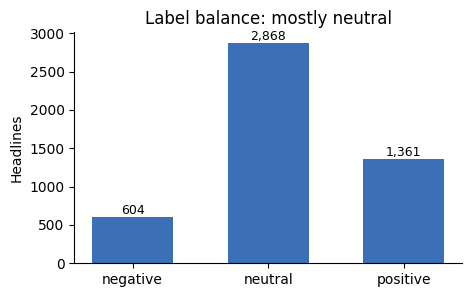

In [10]:
counts = df["sentiment"].value_counts().reindex(LABELS)
print((counts / counts.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color="#3b6fb6", width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Label balance: mostly neutral")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

            count  mean   std  min   25%   50%   75%   max
sentiment                                                 
negative    604.0  23.9   9.9  5.0  17.0  22.0  30.0  56.0
neutral    2868.0  22.1   9.8  2.0  15.0  21.0  28.0  81.0
positive   1361.0  24.7  10.1  5.0  17.0  23.0  31.0  57.0


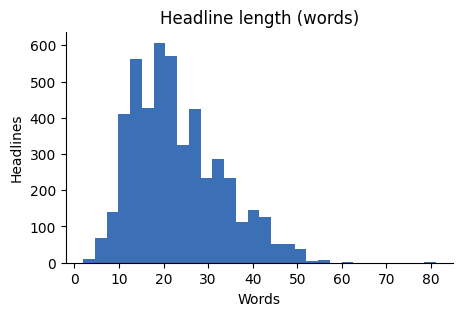

In [11]:
df["words"] = df["headline"].str.split().str.len()
print(df.groupby("sentiment")["words"].describe().round(1))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(df["words"], bins=30, color="#3b6fb6")
ax.set_title("Headline length (words)")
ax.set_xlabel("Words")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [12]:
# Fixed seed, stratified. Few-shot examples and the supervised baseline
# use only `train`; `test` is never shown to a model before scoring.
train, test = train_test(df, n=300)
test.to_csv("data/kaggle/test_sample.csv", index=False)
print("Train:", len(train), "| Test:", len(test))
test["sentiment"].value_counts()


Train: 4533 | Test: 300


,count
sentiment,
neutral,178
positive,84
negative,38


## A3. Classifier evaluation: keyword baseline vs LLM

The LLM classifier is scored on the fixed 300-headline held-out sample with
a sentiment-only prompt. The live news chain uses a longer prompt that also
asks for relevance, but the Kaggle headlines have no target company, so that
instruction would only add noise here. Because LLM output varies between
runs (about 2 points of accuracy at n = 300), the score is the mean of
three runs.

In [13]:
from src.chains.kaggle import keyword_baseline, score, to_articles
from src.chains.news_chain import (
    CLASSIFY_SENTIMENT_SYSTEM,
    classify,
    coverage,
)

METRICS = ("accuracy", "macro_f1")
N_RUNS = 3  # LLM output varies run to run; report the mean, not one draw

keyword_pred = list(test["headline"].map(keyword_baseline))
base = score(test["sentiment"], keyword_pred)
print("Keyword baseline:", {k: base[k] for k in METRICS})

articles = to_articles(test)
runs, zero_preds = [], []
for r in range(N_RUNS):
    labels = classify(articles, system=CLASSIFY_SENTIMENT_SYSTEM)
    missing = coverage(labels, articles)["missing_ids"]
    pred = [
        labels.get(i, {}).get("sentiment", "neutral")
        for i in range(len(test))
    ]
    zero_preds.append(pred)
    runs.append(score(test["sentiment"], pred))
    print(
        f"LLM run {r + 1}:",
        {k: runs[-1][k] for k in METRICS},
        f"| unlabeled: {len(missing)}",
    )

mean = {k: round(sum(s[k] for s in runs) / N_RUNS, 3) for k in METRICS}
print("LLM mean of", N_RUNS, "runs:", mean)

llm = runs[-1]  # last run's per-class report and confusion matrix
print(llm["report"])


Keyword baseline: {'accuracy': 0.687, 'macro_f1': 0.575}
LLM run 1: {'accuracy': 0.837, 'macro_f1': 0.842} | unlabeled: 0
LLM run 2: {'accuracy': 0.823, 'macro_f1': 0.822} | unlabeled: 0
LLM run 3: {'accuracy': 0.843, 'macro_f1': 0.85} | unlabeled: 0
LLM mean of 3 runs: {'accuracy': 0.834, 'macro_f1': 0.838}
              precision    recall  f1-score   support

    negative       0.90      0.95      0.92        38
     neutral       0.88      0.85      0.87       178
    positive       0.75      0.77      0.76        84

    accuracy                           0.84       300
   macro avg       0.84      0.86      0.85       300
weighted avg       0.84      0.84      0.84       300



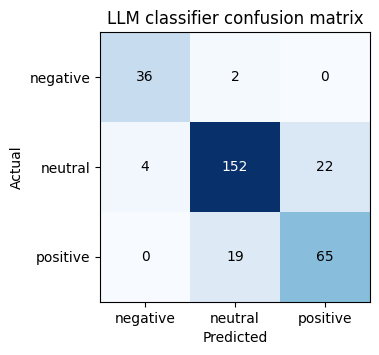

In [14]:
cm = llm["confusion"]

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)
ax.set_title("LLM classifier confusion matrix")
plt.show()

## A4. Classifier diagnostics: supervised baseline, few-shot prompts, agreement

Three checks on the zero-shot LLM classifier above:

1. **A supervised baseline.** A pretrained model can be applied to a task
   by prompting it or by training on labeled data (Jurafsky & Martin, 2026,
   Section 9.4). TF-IDF with logistic regression, trained on the same
   train split, stands in for the second, so the LLM is compared with a
   model that learned from these labels and not only with keywords.
2. **Few-shot prompting.** Two demonstrations per label are added to the
   prompt, drawn from the train split, as Brown et al. (2020, Section 2.4)
   draw conditioning examples from the training set and never from the
   test set. Demonstrations come from sentences every annotator agreed
   on, and K is fixed in advance rather than tuned on the test set. The
   sentiment definition in the prompt now restates the PhraseBank
   annotation guideline: judge only what the sentence states, from an
   investor's view of the stock price (Malo et al., 2014).
3. **Majority vote across runs.** The three runs per prompt are combined
   by majority vote, the self-consistency idea of keeping the answer most
   samples agree on (Wang et al., 2023). It reuses the runs already made,
   so it adds no API calls.

Finally, accuracy is broken down by annotator agreement. If the model is
far more accurate where every annotator agreed, many remaining "errors"
are sentences that people also labeled differently.


In [15]:
from src.chains.kaggle import (
    fewshot_examples,
    load_agreement,
    majority_vote,
    score_by_agreement,
    tfidf_baseline,
)

agreement = load_agreement()
print("Sentences with an agreement band:", len(agreement))

tfidf_pred = tfidf_baseline(train, test)

examples = fewshot_examples(train, per_label=2, agreement=agreement)
print("Few-shot demonstrations (train split, unanimous labels):")
for text, label in examples:
    print(f"  {label:>8}: {text[:90]}")

few_preds = []
for r in range(N_RUNS):
    labels = classify(
        articles, system=CLASSIFY_SENTIMENT_SYSTEM, examples=examples
    )
    few_preds.append(
        [
            labels.get(i, {}).get("sentiment", "neutral")
            for i in range(len(test))
        ]
    )

candidates = {
    "keyword": [keyword_pred],
    "tf-idf + logistic regression": [tfidf_pred],
    "LLM zero-shot": zero_preds,
    "LLM few-shot": few_preds,
}
rows = []
for name, preds in candidates.items():
    per_run = [score(test["sentiment"], p) for p in preds]
    vote = score(test["sentiment"], majority_vote(preds))
    rows.append(
        {
            "classifier": name,
            "runs": len(preds),
            **{
                f"{m} (mean)": round(
                    sum(s[m] for s in per_run) / len(preds), 3
                )
                for m in METRICS
            },
            **{f"{m} (vote)": vote[m] for m in METRICS},
        }
    )
comparison = pd.DataFrame(rows)
comparison


Sentences with an agreement band: 4835
Few-shot demonstrations (train split, unanimous labels):
  negative: The fair value of the company 's investment properties went down to EUR 2.768 billion at t
  negative: At 1411 CET , ArcelorMittal had lost 7.26 % to EUR 17.38 on Euronext Paris , coming at the
   neutral: Cramo Plc is a service company specialising in construction machinery and equipment rental
   neutral: The building will house product development and test laboratories .
  positive: Section : Regional News - The demand in Finnair 's Asian traffic , measured in passenger k
  positive: The Group also has a strong global position in other fishing categories .


,classifier,runs,accuracy (mean),macro_f1 (mean),accuracy (vote),macro_f1 (vote)
0,keyword,1,0.687,0.575,0.687,0.575
1,tf-idf + logistic regression,1,0.793,0.771,0.793,0.771
2,LLM zero-shot,3,0.834,0.838,0.840,0.843
3,LLM few-shot,3,0.827,0.833,0.840,0.850


Test sentences per band: {'100%': 149, '75-99%': 71, '66-74%': 42, '50-65%': 38}


classifier,LLM few-shot (vote),LLM zero-shot (vote),tf-idf + LR
band,,,
100%,0.960,0.946,0.899
75-99%,0.859,0.887,0.775
66-74%,0.762,0.714,0.762
50-65%,0.421,0.474,0.447


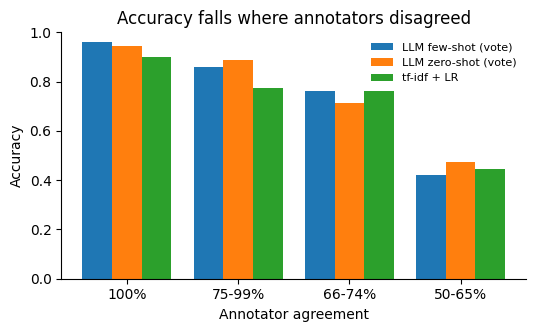

In [16]:
final_preds = {
    "tf-idf + LR": tfidf_pred,
    "LLM zero-shot (vote)": majority_vote(zero_preds),
    "LLM few-shot (vote)": majority_vote(few_preds),
}
by_band = pd.concat(
    score_by_agreement(test, p, agreement).assign(classifier=name)
    for name, p in final_preds.items()
)
band_order = ["100%", "75-99%", "66-74%", "50-65%"]
acc = by_band.pivot(index="band", columns="classifier", values="accuracy")
acc = acc.reindex([b for b in band_order if b in acc.index])
counts = by_band.drop_duplicates("band").set_index("band")["n"]
print("Test sentences per band:", counts.reindex(acc.index).to_dict())
display(acc)

fig, ax = plt.subplots(figsize=(6, 3.2))
width = 0.8 / len(acc.columns)
for j, name in enumerate(acc.columns):
    offset = (j - (len(acc.columns) - 1) / 2) * width
    xs = [i + offset for i in range(len(acc))]
    ax.bar(xs, acc[name], width, label=name)
ax.set_xticks(range(len(acc)), acc.index)
ax.set_xlabel("Annotator agreement")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Accuracy falls where annotators disagreed")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()


**Reading the results (run of October 18, 2026).** The zero-shot LLM
reached 0.834 accuracy and 0.838 macro-F1 (mean of three runs), against
0.793 and 0.771 for TF-IDF with logistic regression and 0.687 and 0.575 for
the keyword baseline. Neutral recall rose from 0.72 in the October 14 run
to 0.85. That run used the earlier prompt and a test sample drawn before
the extra de-duplication, so the gain combines the guideline-based
sentiment definition with the cleaning. Few-shot demonstrations did not
help (0.827 and 0.833): once the label definition is explicit, two
examples per class add little. The majority vote raised the zero-shot
scores slightly, to 0.840 and 0.843.

Every classifier loses accuracy as annotator agreement falls. The
zero-shot LLM is right on 95% of the sentences every annotator agreed on
but on 47% of those where only 50-65% agreed, and TF-IDF and few-shot fall
to similar levels there. The lowest band is a ceiling set by the labels,
not only by the model.

One caveat: the Financial PhraseBank has been public since 2014, so the
LLM may have seen these sentences during pre-training. Brown et al.
(2020, Section 4) show that such test-set contamination can inflate
benchmark scores, so the LLM's numbers may be optimistic for live news.


# Part B. Agent run

## Agent Design and Workflows

The agent is a LangGraph state graph (`src/graph.py`):

```
ticker -> plan -> route -> specialists -> synthesize -> evaluate --pass--> reflect -> memory
                                                            |                 ^
                                                            +--refine--> optimize
```

| Requirement | Where | Printed below |
|---|---|---|
| Plans research steps | `agents/planner.py` | B2 |
| Uses tools dynamically | `agents/toolkit.py`, `tools/` | B3 |
| Routing | `agents/router.py` | B4 |
| Prompt chaining | `chains/news_chain.py` | B5 |
| Evaluator-optimizer | `agents/evaluator.py` | B7 |
| Self-reflection | `agents/evaluator.py: reflect` | B9 |
| Learns across runs | `memory/store.py` | B10 |

This part runs the agent once on NVDA and prints the output of every step
from the run trace, then runs it a second time to show memory in use.
Memory is cleared first so B2 is a true first run.


## B1. Setup check: every tool returns data


In [17]:
print("Chunks indexed:", index_filings(TICKERS))
pd.DataFrame({t: quick_smoke(t) for t in TICKERS})

Chunks indexed: 566


,NVDA,JPM,XOM
get_price_history,ok,ok,ok
get_key_stats,ok,ok,ok
get_financials,ok,ok,ok
get_macro_snapshot,ok,ok,ok
get_news,ok,ok,ok


## B2. Research plan

The planner reads memory first. On the first run of a ticker there are no
notes; later runs show the lessons it used.

In [18]:
# Start from empty memory so the first run below is a true first run.
store.NOTES_PATH.unlink(missing_ok=True)
print("Lessons in memory:", len(store.load_notes()))


Lessons in memory: 0


In [19]:
TICKER = "NVDA"
notes_before = store.load_notes()

report, trace, state = run_agent(TICKER)

print("Sector:", state["sector"])
print("Hypothesis:", state["plan"].hypothesis)
show.plan_table(trace)

Sector: Technology
Hypothesis: Can Nvidia sustain its premium valuation given continued AI-driven demand growth against rising competitive, regulatory, and customer-concentration risks?


,id,task,tool,purpose,priority
0,1,"Pull current valuation multiples, margins, ROE, and analyst price targets/ratings for NVDA.",get_key_stats,Establishes baseline valuation and market expectations to assess if growth justifies the premium.,high
1,2,"Retrieve annual income statement, balance sheet, and cash flow data for the past several years.",get_financials,"Assess revenue growth trajectory, margin trends, R&D spend, and balance sheet strength to validate fundamental growt...",high
2,3,"Analyze 5-year daily price history for returns, volatility, beta vs SPY, and moving averages.",get_price_history,"Understand market behavior, risk profile, and momentum trends relative to broader market.",high
3,4,Gather recent news headlines on Nvidia from the last 30 days.,get_news,"Capture latest developments on product launches, export controls, competitive moves, or earnings surprises that coul...",high
4,5,"Search the latest 10-K for risk factors related to customer concentration, export restrictions, and competition.",search_filings,"Identify disclosed risks around China export controls, hyperscaler customer concentration, and competitive threats f...",high
5,6,Search the latest 10-K MD&A for management commentary on AI demand sustainability and supply chain constraints.,search_filings,"Understand management's own view on demand durability and potential supply-side bottlenecks (e.g., TSMC capacity, HB...",medium
6,7,"Retrieve current macro snapshot including CPI, Fed funds rate, 10-year yield, and GDP trends.",get_macro_snapshot,"Contextualize how macro conditions (rates, growth) could affect capex cycles from Nvidia's hyperscaler customers and...",medium


In [20]:
show.memory_read(trace)

No prior lessons: first run for this ticker and sector.


,lesson


## B3. Tool calls (dynamic tool use)

The plan, not the code, decides which tools run and with what query.
The three specialists run in parallel, so the log is grouped by the
specialist (`route`) that made each call.


In [21]:
show.tool_log(trace)

,route,tool,args,ok,rows,error
0,earnings,get_key_stats,{},True,14,None
1,earnings,get_financials,{},True,12,None
2,earnings,search_filings,"{'query': 'Search the latest 10-K for risk factors related to customer concentration, export restrictions, and compe...",True,3,None
3,earnings,search_filings,{'query': 'Search the latest 10-K MD&A for management commentary on AI demand sustainability and supply chain constr...,True,3,None
4,market,get_price_history,{},True,7,None
5,market,get_macro_snapshot,{},True,5,None
6,news,get_news,{},True,99,None


## B4. Routing decisions

In [22]:
show.routing_table(trace)

,step_id,route,reason
0,1,earnings,"This task focuses on NVDA’s valuation multiples, profitability margins, ROE, and analyst expectations, which are fin..."
1,2,earnings,"Retrieving multi-year income statements, balance sheets, and cash flow data to assess revenue growth, margins, R&D s..."
2,3,market,"Analyzing five-year daily returns, volatility, beta versus SPY, and moving averages concerns price action, risk, and..."
3,4,news,"This task requests recent Nvidia headlines and developments from the last 30 days, which falls under news research."
4,5,earnings,"This task searches the latest 10-K for disclosed risks involving customer concentration, export restrictions, and co..."
5,6,earnings,This task requires searching a company’s latest 10-K MD&A for management commentary on AI demand durability and supp...
6,7,market,"This task requests current macro indicators and their implications for tech valuations and hyperscaler capex cycles,..."


## B5. News prompt chain: output of each step

The digest's `net_sentiment` is not the model's opinion: the chain counts
the per-article labels from the classify step and applies majority rule
with a 15-point margin (`sentiment_counts` is printed with the summary).
Empty `figures` lists in the extract step are expected for headline-only
items; the extractor only reports numbers that appear in the text.


In [23]:
show.news_chain_steps(trace)


=== INGEST ===
{
 "n": 99,
 "sample": [
  "Nvidia says its new AI safety platform can contain rogue agents within \u2018milliseconds\u2019",
  "Nvidia launches agent safety platform backed by over 100 companies",
  "Nvidia commits $250M of compute to UK AI safety research",
  "Nvidia adds a record $150bn to its share buyback",
  "Nvidia-backed Reflection unveils Beam, its first open-weight model"
 ],
 "earliest": "2026-09-18T10:00:37Z",
 "latest": "2026-10-16T19:30:03Z"
}

=== PREPROCESS ===
{
 "n_in": 99,
 "n_out": 95,
 "duplicate": 0,
 "non_news": 1,
 "stale": 3,
 "no_mention": 0
}

=== CLASSIFY ===
{
 "0": {
  "id": 0,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "1": {
  "id": 1,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "2": {
  "id": 2,
  "topic": "other",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "3": {
  "id": 3,
  "topic": "other",
  "sentiment": "positive",
  "relevance": "high"
 },
 "4": {
  "id": 4,


## B6. Specialist findings

In [24]:
show.findings_table(trace)

,route,summary,key_figures,risks
0,market,"NVDA closed at $214.13, down 2.38% over the past month but up 19.07% over the past year, with annualized volatility ...","[Last close: $214.13, 1-month return: -2.38%, 1-year return: +19.07%, Annualized volatility: 37.27%, Beta vs SPY: 2....","[High beta (2.128) means NVDA amplifies broader market swings, increasing downside risk in a risk-off environment., ..."
1,earnings,"NVDA's FY2026 (ended Jan 31, 2026) revenue was $215.94B, up from $130.50B in FY2025, with operating income of $130.3...","[Revenue FY2026: $215.938B, Revenue FY2025: $130.497B, Operating Income FY2026: $130.387B (60.4% margin), Operating ...","[Customer concentration: ""A significant amount of our revenue stems from a limited number of partners and distributo..."
2,news,"NVDA sentiment is neutral, reflecting the large majority of neutral-labeled coverage, especially around product and ...","[The dominant coverage is neutral, led by Nvidia’s launch of its Open Agent Safety Platform, with several reports de...","[Authorities have accused a California man of smuggling about $300 million in Nvidia chips to China, highlighting ex..."


## B7. Evaluator-optimizer loop

The evaluator (a different model family from the writer) scores the draft
1-5 on five criteria and lists critiques; the optimizer rewrites the draft
to address them. Every draft gets at least one revision
(`MIN_ITERATIONS = 1`), then the loop stops once the average reaches 4.0
or after three rounds. Iteration 0 is the first draft; iteration 1 is the
revised one.

In [25]:
show.evaluation_history(state)

,iteration,average,completeness,evidence,accuracy,balance,clarity
0,0,4.2,4,4,5,5,3
1,1,4.6,5,4,5,5,4


In [26]:
show.critiques(state)


Iteration 0 (avg 4.2):
  - Add customer concentration and third-party supplier dependence to the bear case; both are explicit filing risks.
  - Qualify the claim that the secular AI demand story “remains intact.” The findings include demand-related news reports, but no filing commentary establishing demand sustainability.
  - Describe inventory buildup as a commentary concern, not an established condition; the findings do not confirm that inventory is sitting unsold.
  - Avoid saying FY2026 free cash flow “funds” the entire additional $150B buyback authorization. Distinguish an authorization from actual repurchases and available cash.
  - Condense repeated fundamentals, risks, and macro points so a portfolio manager can reach the thesis and key decision factors within two minutes.

Iteration 1 (avg 4.6):
  - Remove or substantiate “industry-leading margins”; the findings contain no peer comparison.
  - Qualify the claim that cash and free cash flow provide capacity to execute the $150

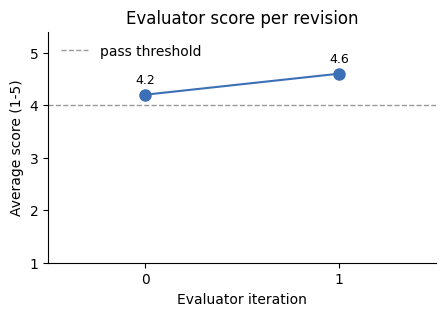

In [27]:
show.plot_scores(state)
plt.show()

## B8. Final report

In [28]:
display(show.report_markdown(report))

# NVDA research brief

**Thesis:** NVDA's FY2026 results were exceptional: revenue +65% to \$215.9B, EPS \$4.90, \$96.7B FCF, and a pristine balance sheet (0.07x D/E, 117% ROE) at a 13.5x forward P/E. However, rising 10-year yields (5.10%), high beta (2.13), and filing-disclosed customer-concentration/supply-chain risks warrant caution. Technicals show a near-term pullback below the 50-day SMA, and reported demand strength (China, SpaceX, partnerships) is promising but not confirmed by filing commentary—size positions accordingly.

## Bull case
- FY2026 revenue grew 65% YoY to \$215.9B with 60.4% operating margin and \$120.1B net income, demonstrating exceptional scale economics
- \$96.7B FCF and \$10.6B cash provide ample flexibility and capacity to execute the newly authorized \$150B buyback, though the authorization itself is separate from actual repurchase spend
- Extremely low leverage (debt/equity 0.07x) and 117.2% trailing ROE reflect a highly efficient, capital-light business model
- Forward P/E of 13.5x versus trailing P/E of 27.1x implies continued earnings growth expectations; consensus is 'strong buy' with a \$328.72 mean target (~54% upside from \$214.13)
- News reports point to demand signals including potential China sales, SpaceX's reported AI-chip purchase plans, and new partnerships (Microsoft Surface, Adobe), though these are media reports rather than filed guidance

## Bear case
- Filings disclose meaningful customer concentration, with revenue dependent on a limited number of partners/distributors whose loss could materially harm results
- Dependence on third-party suppliers for manufacturing, assembly, and testing reduces control over yields, quality, and delivery, with disclosed risk of supply/demand mismatches
- Rising 10-year Treasury yield (5.10% from 4.05%) pressures high-multiple growth valuations, compounded by high beta (2.128) and elevated volatility (37.27%)
- Regulatory overhang from antitrust inquiries (EU, US, UK, China, South Korea) and export-control enforcement actions (e.g., a \$300M chip-smuggling case to China)
- Media commentary flags potential inventory buildup ('revenue sitting in warehouses') and rising AMD competition in data-center chips—concerns not corroborated by filing disclosures but worth monitoring

## Fundamentals
NVDA's FY2026 revenue rose 65% to \$215.9B with net income of \$120.1B (55.6% margin), a slight compression from FY2025 (62.4% operating, 55.8% net margin). Diluted EPS grew 67% to \$4.90. The balance sheet remains pristine: debt/equity of 0.07x, \$10.6B cash, \$102.7B operating cash flow, and \$96.7B FCF on modest \$6.0B capex. Valuation shows trailing P/E of 27.1x compressing to a forward 13.5x, with P/B of 22.6x and ROE of 117.2%; the 0.47% dividend yield is immaterial to the thesis. Filings also disclose customer-concentration and third-party supplier-dependence risks that are structural to the business model.

## News and catalysts
Coverage is predominantly neutral, centered on the Open Agent Safety Platform launch. Positive catalysts include an additional \$150B buyback authorization (not yet executed spend), a share-price record, and partnerships with Microsoft (Surface) and Adobe. Demand-side reports cite potential China sales and SpaceX's reported plans to finance a large AI-chip purchase, though these remain unconfirmed by company filings. Risks in the news flow include a \$300M export-control smuggling case to China, a high-severity GPU monitoring vulnerability, commentary questioning whether revenue is sitting unsold in inventory (an unconfirmed concern), and intensifying AMD competition in data-center chips.

## Market and macro
NVDA closed at \$214.13, down 2.38% over the past month but up 19.07% over the past year, trading below its 50-day SMA (\$223.08) yet above its 200-day SMA (\$202.97)—a near-term pullback within a longer-term uptrend. High beta (2.128) and elevated volatility (37.27% annualized) make the stock highly sensitive to macro shifts. The backdrop is mixed: Fed funds rate eased to 3.75%, unemployment fell to 4.2%, and real GDP grew ~2.19% YoY, but the 10-year Treasury yield jumped to 5.10% from 4.05% and CPI remains elevated at 3.72% YoY, pressuring valuations for high-multiple growth names like NVDA.

## Conclusion
NVDA's fundamentals are exceptional—rapid growth, industry-leading margins, a fortress balance sheet, and a reasonable forward multiple—supporting the bullish consensus. However, filing-disclosed customer-concentration and supplier-dependence risks, a challenging rate environment, high volatility/beta, and unconfirmed demand/inventory signals in the news warrant caution on timing and sizing. The long-term AI growth narrative is supported by news flow but not yet corroborated by filing commentary on demand sustainability, so investors should weigh strong fundamentals against elevated and partly unverified risk factors. Analysis only; not investment advice.

*Analysis only; not investment advice.*

## B9. Reflection (self-assessment of output and process)

In [29]:
show.reflection_view(state)

{'weakest_section': 'News and catalysts / demand narrative',
 'unsupported_claims': ["SpaceX's reported plans to finance a large AI-chip purchase is stated as a demand signal without sourcing detail or corroboration beyond news aggregation",
  "'Potential China sales' is treated as a positive catalyst despite being unconfirmed and in tension with disclosed export-control enforcement risk",
  'Mean price target upside of ~54% is presented without discussing analyst target dispersion, revision trends, or methodology caveats',
  "Inventory buildup ('revenue sitting in warehouses') is flagged as a risk but given no quantitative backing (e.g., days inventory outstanding, channel inventory data) despite having financial data access"],
 'missing_data': ["No inventory/DSO or channel-inventory metrics to assess the 'revenue sitting in warehouses' claim quantitatively",
  'No segment-level revenue breakdown (data center vs. gaming vs. automotive) to assess customer concentration risk more precis

## B10. Memory: what this run taught the agent

New lessons written to `memory/notes.json`, then a second run on the same
ticker to show the planner reading them.

In [30]:
show.memory_diff(trace)

,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-18,"For semiconductor/AI-hardware companies, always pull segment revenue and inventory/DSO metrics to substantiate or re..."
1,NVDA,Technology,2026-10-18,"Distinguish clearly in the brief between filing-sourced facts and news-sourced claims, and actively attempt to verif..."
2,NVDA,Technology,2026-10-18,"When citing analyst price targets, include dispersion/range and recent revision direction, not just the mean, to avo..."
3,NVDA,Technology,2026-10-18,"For high-beta/high-multiple growth stocks, pair macro rate commentary with valuation sensitivity (e.g., DCF or multi..."
4,NVDA,Technology,2026-10-18,"Retrieve MD&A/management commentary sections specifically, not just risk-factor boilerplate, since risk factors are ..."


In [31]:
report2, trace2, state2 = run_agent(TICKER)
print("Lessons the planner read on run 2:")
display(show.memory_read(trace2))
print("Run 1 steps:", [s.tool for s in state["plan"].steps])
print("Run 2 steps:", [s.tool for s in state2["plan"].steps])
print("Run 1 final score:", state["history"][-1]["average"],
      "| Run 2 final score:", state2["history"][-1]["average"])

Lessons the planner read on run 2:


,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-18,"For semiconductor/AI-hardware companies, always pull segment revenue and inventory/DSO metrics to substantiate or re..."
1,NVDA,Technology,2026-10-18,"Distinguish clearly in the brief between filing-sourced facts and news-sourced claims, and actively attempt to verif..."
2,NVDA,Technology,2026-10-18,"When citing analyst price targets, include dispersion/range and recent revision direction, not just the mean, to avo..."
3,NVDA,Technology,2026-10-18,"For high-beta/high-multiple growth stocks, pair macro rate commentary with valuation sensitivity (e.g., DCF or multi..."
4,NVDA,Technology,2026-10-18,"Retrieve MD&A/management commentary sections specifically, not just risk-factor boilerplate, since risk factors are ..."


Run 1 steps: ['get_key_stats', 'get_financials', 'get_price_history', 'get_news', 'search_filings', 'search_filings', 'get_macro_snapshot']
Run 2 steps: ['get_financials', 'get_key_stats', 'get_news', 'search_filings', 'search_filings', 'get_price_history', 'get_macro_snapshot']
Run 1 final score: 4.6 | Run 2 final score: 4.6


# Part C. Evaluation

## Evaluation and Iteration

Part B showed one evaluator-optimizer loop. This part measures the agent
against alternatives, all scored with the same rubric and the same
findings so the comparison is fair.

The numeric spot-check (`unsupported_*`) counts figures in a brief that
appear in no finding. A figure the writer labels as calculated (for
example "a calculated ~65% increase") is exempt: the evaluator asks for
that label, and such figures are arithmetic on the findings rather than
claims needing their own source. The baseline never sees the findings,
so its evidence and accuracy scores are structurally low; the comparison
measures whether tools and the loop produce a grounded brief.


## C1. Three comparisons

Three comparisons, all scored with the same rubric and the same findings:

1. **Baseline vs agent:** a single prompt with no tools, no plan, no loop.
2. **Numeric spot-check:** figures in each brief that appear in no finding.
3. **Memory on vs off:** the same ticker with memory disabled.

In [32]:
rows = []
for t in TICKERS:
    rep, tr, st = run_agent(t)
    base = baseline_brief(t)
    base_score = score_against_findings(base, st["findings"])
    findings = st["findings"]
    rows.append(
        {
            "ticker": t,
            "baseline_avg": base_score["average"],
            "agent_first_draft": st["history"][0]["average"],
            "agent_final": st["history"][-1]["average"],
            "iterations": len(st["history"]),
            "tool_success": tool_success_rate(tr),
            "unsupported_baseline": len(unsupported_figures(base, findings)),
            "unsupported_agent": len(
                unsupported_figures(st["draft"], findings)
            ),
        }
    )
results = pd.DataFrame(rows)
results

,ticker,baseline_avg,agent_first_draft,agent_final,iterations,tool_success,unsupported_baseline,unsupported_agent
0,NVDA,2.0,4.4,4.4,2,1.0,3,11
1,JPM,1.8,4.2,4.4,2,1.0,9,3
2,XOM,1.8,4.2,4.4,2,1.0,20,13


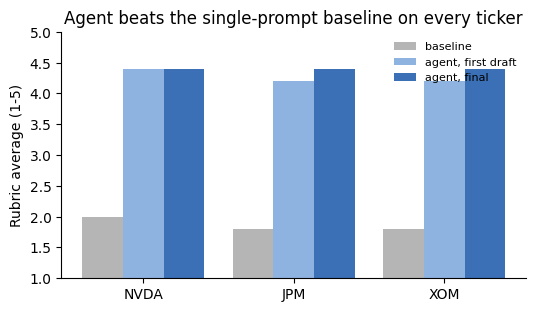

In [33]:
fig, ax = plt.subplots(figsize=(6, 3.2))
x = list(range(len(results)))
w = 0.27
series = [
    ("baseline_avg", "baseline", "#b5b5b5", -w),
    ("agent_first_draft", "agent, first draft", "#8fb3e0", 0),
    ("agent_final", "agent, final", "#3b6fb6", w),
]
for col, label, color, offset in series:
    ax.bar([i + offset for i in x], results[col], w, label=label, color=color)
ax.set_xticks(x, results["ticker"])
ax.set_ylim(1, 5)
ax.set_ylabel("Rubric average (1-5)")
ax.set_title("Agent beats the single-prompt baseline on every ticker")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [34]:
_, tr_off, st_off = run_agent(TICKER, use_memory=False)
_, tr_on, st_on = run_agent(TICKER, use_memory=True)
pd.DataFrame([
    {"memory": "off", "plan_steps": len(st_off["plan"].steps),
     "notes_read": len(tr_off.select("memory", "read")[0].output),
     "final_score": st_off["history"][-1]["average"]},
    {"memory": "on", "plan_steps": len(st_on["plan"].steps),
     "notes_read": len(tr_on.select("memory", "read")[0].output),
     "final_score": st_on["history"][-1]["average"]},
])

,memory,plan_steps,notes_read,final_score
0,off,7,0,4.2
1,on,8,8,4.4


In [35]:
show.timing_table(trace)

,seconds
step,
evaluator,13.7
optimizer,27.4
planner,12.6
reflection,14.1
router,14.7
specialist,90.4
specialists,57.3
synthesizer,20.8


## C2. Limitations

- Figures come from free data sources (`yfinance` is unofficial; NewsAPI
  caps at 100 articles) and are cached, so a run reflects the cache date.
- The evaluator is an LLM and its scores vary by about 0.2 between runs.
- The agent has no view of future events, and the brief is analysis only,
  not investment advice.

## Impact of the NLP-track changes (PR #5)

This notebook was run end to end on branch `nlp-track-ashley` on October 18,
2026, with the agent and evaluator code unchanged. Differences from the
October 14 run on `main` therefore come from the NLP-track changes and from
run-to-run variation.

| Measure | Oct 14 (`main`) | Oct 18 (`nlp-track-ashley`) |
|---|---|---|
| Classifier accuracy / macro-F1, mean of 3 runs (A3) | 0.804 / 0.810 | 0.834 / 0.838 |
| Classifier neutral recall (A3) | 0.72 | 0.85 |
| TF-IDF + logistic regression baseline (A4) | not run | 0.793 / 0.771 |
| NVDA news window (B5) | newest items; first five within 40 minutes | Sep 18 to Oct 16 |
| NVDA news labels, positive / neutral / negative (B5) | 61 / 15 / 10, net positive | 19 / 60 / 13, net neutral |
| News items left unlabeled by the model (B5) | not tracked | 0 of 95 |
| NVDA evaluator loop, first draft to revision (B7) | 3.6 to 4.6 | 4.2 to 4.6 |
| Agent final score, NVDA / JPM / XOM (C1) | 4.4 / 4.4 / 4.6 | 4.4 / 4.4 / 4.4 |
| Single-prompt baseline, NVDA / JPM / XOM (C1) | 2.2 / 1.8 / 2.0 | 2.0 / 1.8 / 1.8 |
| Unsupported figures in agent briefs, NVDA / JPM / XOM (C1) | 1 / 5 / 3 | 11 / 3 / 13 |
| Memory off to on, final score (C1) | 4.4 to 4.4 | 4.2 to 4.4 |
| Specialists, summed time / wall time | 201 s / 170 s | 90 s / 57 s |

**Reading the table.**

- **Classifier.** Accuracy and neutral recall improved. The gain combines
  the guideline-based sentiment definition with the stricter cleaning,
  which changed the test sample slightly.
- **NVDA news sentiment** moved from net positive to net neutral. Two
  changes act together here: the new sentiment definition, and NewsAPI
  results requested by relevance, which now cover four weeks instead of
  the latest hours. This run cannot separate the two.
- **Agent scores** moved by at most 0.2, within the evaluator's run-to-run
  variation, so the NLP changes alter the findings without measurably
  changing how briefs are judged. Changes to the evaluator can therefore be
  assessed on top of this run.
- **Unsupported figures** rose for NVDA and XOM. The check is an exact
  string match. In the B8 brief, the figures it would flag that can be
  traced are rounded or re-unitized versions of figures in the findings
  ($215.9B for $215.94B; $150B for a "$150 billion" buyback) or unlabeled
  calculations (CPI up 3.72% year over year, computed from the FRED index
  levels). A figure-by-figure check of the C1 briefs is still needed before
  reading the rise as a quality change.
- **Speed.** Specialist wall time fell by about two thirds with a similar
  number of headlines (99 against 100), consistent with the classify and
  extract batches now running concurrently.


## Summary

- **Baseline vs agent.** The single-prompt baseline has no tools, so its
  figures cannot be checked against findings; the agent's can, and the
  `unsupported_*` columns above count figures that appear in no finding.
- **Evaluator-optimizer.** Every draft gets at least one revision; the
  B7 critiques and the B8 report show what changed.
- **Memory.** The score is similar with memory on and off; the benefit
  shows in the plan (extra filing searches and news cross-checks that
  answer the previous run's lessons), not in the rubric average.
- **Robustness.** Each tool call is wrapped so a failed API degrades the
  brief instead of ending the run, and a model that keeps returning
  truncated JSON is retried on the other provider.
- **Speed.** The three specialists run in parallel; the timing table
  shows their summed time (`specialist`) against their wall time
  (`specialists`).
- **Known limits.** The reflection step inherits the model's priors and
  has flagged correct current data (a 10-year yield above 5%, an analyst
  target well above the price) as suspicious; segment-level revenue and
  peer comparables are the data gaps it raises on every run.
